# Part 7: A CVaR-Based Objective Alongside Mean-Variance

### Ramith Vaid | NTU Singapore

Every portfolio so far minimizes or trades off variance. Variance treats upside and downside moves alike and says little about the tail, which is what a drawdown or a bad month actually is. This part adds portfolios built on Conditional Value at Risk (CVaR at 95%: the average loss on the worst 5% of days) and asks whether they deliver better tail outcomes out of sample, and whether the GARCH idea that runs through this project helps tail-risk prediction too.

**Portfolios** (long only, fully invested, 35% cap, 10 bps costs, 5-year training, 6-month test, same 15 windows):
- *Max Sharpe (sample covariance)*: the project's baseline, with each window's T-bill yield as the risk-free rate (Part 5).
- *Min variance* with the sample covariance and with the GARCH-informed covariance (static correlation).
- *Min CVaR (historical)*: minimizes the CVaR of the 5 years of daily training returns, as a linear program (Rockafellar and Uryasev).
- *Min CVaR (filtered)*: the same, but on filtered historical simulation scenarios. Each asset's training returns are divided by its own GARCH(1,1) conditional volatility and multiplied by the one-day-ahead GARCH volatility forecast, so the scenarios reflect current volatility while keeping the dependence between assets in the historical shocks.
- *Max STARR (historical and filtered)*: maximizes expected excess return per unit of CVaR, the CVaR analogue of Max Sharpe, as a linear program (Charnes-Cooper form). It uses the same noisy five-year mean returns as Max Sharpe.
- *Equal weight* as the reference.

Both universes from Part 4 (8 stocks, 13 assets) are run. Besides return, volatility, Sharpe against the T-bill and maximum drawdown, the outcomes that matter here are the realized 95% CVaR of daily returns, the worst six-month window and turnover. The last section asks a prediction question separately: for the same fixed portfolios, is the CVaR predicted from filtered scenarios closer to the CVaR realized over the next six months than the CVaR predicted from plain historical scenarios? Scenario returns are daily log returns treated as simple returns. The data end date is pinned to 2026-10-13.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from portfolio_utils import (
    load_or_build_window_inputs, window_risk_free, get_rolling_windows, max_sharpe_portfolio, min_variance_portfolio,
    min_cvar_portfolio, max_starr_portfolio, filtered_scenarios, portfolio_cvar, simulate_given_weights, risk_summary,
    drawdown_path, bootstrap_sharpe_differences
)
print('Libraries loaded.')

Libraries loaded.


## 1. Data

In [2]:
tickers8 = ['JPM', 'AAPL', 'XOM', 'JNJ', 'PG', 'CAT', 'NEE', 'AMZN']
tickers13 = tickers8 + ['VNQ', 'TLT', 'EFA', 'EEM', 'GLD']
START, END = '2014-01-01', '2026-10-14'  # END is exclusive: last row is 2026-10-13
prices = pd.DataFrame({t: yf.download(t, start=START, end=END, progress=False)['Close'].squeeze() for t in tickers13}).dropna()
log_returns = np.log(prices / prices.shift(1)).dropna()
irx = yf.download('^IRX', start=START, end=END, progress=False)['Close'].squeeze().dropna()
tbill_annual = (irx / 100).clip(lower=0.0).reindex(log_returns.index).ffill().bfill()
rf_daily = tbill_annual / 252
inputs = {8: load_or_build_window_inputs('cache_window_inputs_8.pkl', log_returns, tickers8),
          13: load_or_build_window_inputs('cache_window_inputs_13.pkl', log_returns, tickers13)}
tick = {8: tickers8, 13: tickers13}
windows = get_rolling_windows(log_returns.index)
covid = [w['test_start'] for w in inputs[8]].index(pd.Timestamp('2020-01-07').date())
print(f'{len(windows)} windows; COVID window is window {covid + 1}')

15 windows; COVID window is window 3


## 2. Weights for every strategy and window

Each window's weights come from training data only. The linear programs have 1,260 scenario variables each and solve in a fraction of a second.

In [3]:
COST = 0.0010
STRATS = ['Max Sharpe (sample)', 'Min variance (sample)', 'Min variance (GARCH)', 'Min CVaR (historical)', 'Min CVaR (filtered)',
          'Max STARR (historical)', 'Max STARR (filtered)', 'Equal weight']
weights = {n: {s: [] for s in STRATS} for n in (8, 13)}
scen_store = {n: [] for n in (8, 13)}
rf_win = {n: window_risk_free(inputs[n], log_returns, tbill_annual) for n in (8, 13)}
for n in (8, 13):
    for k, (wi, (tr0, tr1, te1)) in enumerate(zip(inputs[n], windows)):
        train = log_returns[tick[n]].iloc[tr0:tr1]
        hist = train.values
        filt = filtered_scenarios(train)
        scen_store[n].append({'hist': hist, 'filt': filt})
        mean_daily = wi['mean'].values / 252
        rf_d = rf_win[n][k] / 252
        weights[n]['Max Sharpe (sample)'].append(max_sharpe_portfolio(wi['mean'], wi['cov']['sample'], n, rf=rf_win[n][k]))
        weights[n]['Min variance (sample)'].append(min_variance_portfolio(wi['mean'], wi['cov']['sample'], n))
        weights[n]['Min variance (GARCH)'].append(min_variance_portfolio(wi['mean'], wi['cov']['garch_static'], n))
        weights[n]['Min CVaR (historical)'].append(min_cvar_portfolio(hist)[0])
        weights[n]['Min CVaR (filtered)'].append(min_cvar_portfolio(filt)[0])
        weights[n]['Max STARR (historical)'].append(max_starr_portfolio(hist, mean_daily - rf_d))
        weights[n]['Max STARR (filtered)'].append(max_starr_portfolio(filt, mean_daily - rf_d))
        weights[n]['Equal weight'].append(np.ones(n) / n)
    print(f'{n} assets: weights built for {len(inputs[n])} windows')

8 assets: weights built for 15 windows


13 assets: weights built for 15 windows


## 3. Out-of-sample results, net of costs

Daily returns of each strategy over the concatenated test windows (January 2019 to July 2026). *Daily CVaR 95%* is the average of the worst 5% of daily returns (shown as a positive loss). *Worst window* is the lowest six-month net return.

In [4]:
rows, series = [], {}
for n in (8, 13):
    tests = [wi['test'] for wi in inputs[n]]
    for s in STRATS:
        wdf, net = simulate_given_weights(tests, weights[n][s], COST)
        series[(n, s)] = net
        m = risk_summary(net, rf_daily)
        k = max(1, int(np.ceil(0.05 * len(net))))
        win_ret = (1 + net).groupby(np.repeat(np.arange(len(tests)), [len(t) for t in tests])).prod() - 1
        rows.append({'universe': f'{n} assets', 'strategy': s, 'return_%': m['ann_return'] * 100, 'vol_%': m['ann_vol'] * 100,
                     'sharpe': m['sharpe'], 'max_dd_%': m['max_drawdown'] * 100, 'daily_cvar95_%': -np.sort(net.values)[:k].mean() * 100,
                     'worst_window_%': win_ret.min() * 100, 'avg_turnover': wdf['turnover'].iloc[1:].mean(),
                     'median_holdings': int(wdf['n_holdings'].median())})
res = pd.DataFrame(rows)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
pd.set_option('display.width', 220)
print(res.to_string(index=False))

 universe               strategy  return_%  vol_%  sharpe  max_dd_%  daily_cvar95_%  worst_window_%  avg_turnover  median_holdings
 8 assets    Max Sharpe (sample)    19.278 21.142   0.782   -28.141           3.085         -17.386         0.383                5
 8 assets  Min variance (sample)    13.939 16.715   0.670   -31.948           2.351          -4.843         0.148                6
 8 assets   Min variance (GARCH)    15.246 16.869   0.741   -32.642           2.395          -9.906         0.544                6
 8 assets  Min CVaR (historical)    14.278 17.046   0.677   -30.454           2.392         -10.040         0.173                6
 8 assets    Min CVaR (filtered)    14.401 17.408   0.670   -32.680           2.538          -9.587         0.597                6
 8 assets Max STARR (historical)    19.543 20.656   0.814   -26.826           2.974         -16.487         0.386                4
 8 assets   Max STARR (filtered)    21.996 19.889   0.968   -27.473           2.919

## 4. How the strategies rank on tail outcomes

Rank (1 = best) of each strategy within its universe on four outcomes: maximum drawdown, daily CVaR, worst six-month window and Sharpe ratio.

In [5]:
ranks = []
for uni, g in res.groupby('universe', sort=False):
    r = pd.DataFrame({'strategy': g['strategy'].values,
                      'rank_max_dd': g['max_dd_%'].rank(ascending=False).values,
                      'rank_cvar': g['daily_cvar95_%'].rank(ascending=True).values,
                      'rank_worst_window': g['worst_window_%'].rank(ascending=False).values,
                      'rank_sharpe': g['sharpe'].rank(ascending=False).values})
    r.insert(0, 'universe', uni)
    ranks.append(r)
ranks = pd.concat(ranks)
print(ranks.to_string(index=False))

 universe               strategy  rank_max_dd  rank_cvar  rank_worst_window  rank_sharpe
 8 assets    Max Sharpe (sample)        3.000      8.000              8.000        4.000
 8 assets  Min variance (sample)        6.000      1.000              1.000        7.000
 8 assets   Min variance (GARCH)        7.000      3.000              4.000        5.000
 8 assets  Min CVaR (historical)        4.000      2.000              5.000        6.000
 8 assets    Min CVaR (filtered)        8.000      4.000              2.000        8.000
 8 assets Max STARR (historical)        1.000      7.000              7.000        3.000
 8 assets   Max STARR (filtered)        2.000      6.000              6.000        2.000
 8 assets           Equal weight        5.000      5.000              3.000        1.000
13 assets    Max Sharpe (sample)        5.000      8.000              8.000        4.000
13 assets  Min variance (sample)        3.000      1.000              3.000        6.000
13 assets   Min varia

### Is the Sharpe difference between objectives distinguishable from chance?

A block bootstrap (5,000 resamples of the test days in 21-day blocks, the same blocks for every strategy) of each strategy's Sharpe ratio, and the share of resamples in which one strategy's Sharpe ratio exceeds another's. With 15 windows and one period, these are rough guides.

In [6]:
pairs = [('Max STARR (filtered)', 'Max Sharpe (sample)'), ('Max STARR (historical)', 'Max Sharpe (sample)'),
         ('Max STARR (filtered)', 'Equal weight'), ('Max STARR (filtered)', 'Max STARR (historical)'),
         ('Min CVaR (historical)', 'Min variance (sample)'), ('Min CVaR (filtered)', 'Min CVaR (historical)'),
         ('Min variance (GARCH)', 'Min variance (sample)')]
boot_rows = []
for n in (8, 13):
    Rn = pd.DataFrame({s: series[(n, s)] for s in STRATS})
    boot = bootstrap_sharpe_differences(Rn, rf_daily, n_boot=5000, block=21, seed=0)
    for a, b in pairs:
        d = boot[a] - boot[b]
        boot_rows.append({'universe': f'{n} assets', 'a': a, 'b': b, 'median_diff': np.median(d), 'ci5': np.percentile(d, 5), 'ci95': np.percentile(d, 95),
                          'P(a > b)': float(np.mean(d > 0))})
boot_df = pd.DataFrame(boot_rows)
print(boot_df.to_string(index=False))

 universe                      a                      b  median_diff    ci5  ci95  P(a > b)
 8 assets   Max STARR (filtered)    Max Sharpe (sample)        0.188  0.022 0.374     0.967
 8 assets Max STARR (historical)    Max Sharpe (sample)        0.030 -0.030 0.086     0.797
 8 assets   Max STARR (filtered)           Equal weight       -0.103 -0.499 0.269     0.330
 8 assets   Max STARR (filtered) Max STARR (historical)        0.158 -0.008 0.343     0.941
 8 assets  Min CVaR (historical)  Min variance (sample)        0.001 -0.157 0.152     0.503
 8 assets    Min CVaR (filtered)  Min CVaR (historical)       -0.007 -0.226 0.210     0.478
 8 assets   Min variance (GARCH)  Min variance (sample)        0.069 -0.122 0.281     0.721
13 assets   Max STARR (filtered)    Max Sharpe (sample)        0.093 -0.089 0.280     0.794
13 assets Max STARR (historical)    Max Sharpe (sample)        0.012 -0.048 0.070     0.622
13 assets   Max STARR (filtered)           Equal weight       -0.017 -0.457 0.39

## 5. Is filtered scenario CVaR a better prediction of the next six months' CVaR?

For three fixed portfolios (equal weight, the Max Sharpe weights and the historical min-CVaR weights), each window's predicted 95% CVaR under (a) the plain 5-year historical scenarios and (b) the filtered scenarios, against the 95% CVaR of the daily returns actually realized over the following six months for the same weights (7 worst of about 126 days, so each realized value is noisy; the comparison is the mean absolute gap over the windows).

In [7]:
rows = []
for n in (8, 13):
    for name, key in (('Equal weight', 'Equal weight'), ('Max Sharpe (sample)', 'Max Sharpe (sample)'), ('Min CVaR (historical)', 'Min CVaR (historical)')):
        for k, wi in enumerate(inputs[n]):
            w = weights[n][key][k]
            real = portfolio_cvar(wi['test'].values, w)
            ph = portfolio_cvar(scen_store[n][k]['hist'], w)
            pf = portfolio_cvar(scen_store[n][k]['filt'], w)
            rows.append({'universe': f'{n} assets', 'portfolio': name, 'window': k + 1, 'realized': real, 'pred_hist': ph, 'pred_filt': pf,
                         'err_hist': abs(ph - real), 'err_filt': abs(pf - real)})
cv = pd.DataFrame(rows)
cv['covid'] = cv['window'] == covid + 1
def summ(frame, label):
    g = frame.groupby(['universe', 'portfolio']).agg(err_hist=('err_hist', 'mean'), err_filt=('err_filt', 'mean'),
                                                      filt_closer=('err_filt', lambda s: 0))
    wins = frame.assign(w=frame['err_filt'] < frame['err_hist']).groupby(['universe', 'portfolio'])['w'].sum()
    g['filt_closer'] = wins
    g[['err_hist', 'err_filt']] *= 100
    g['n_windows'] = frame.groupby(['universe', 'portfolio']).size()
    print(f'--- {label} (mean |predicted - realized| daily CVaR, percentage points)')
    print(g.round(3).to_string())
summ(cv, 'all windows')
print()
summ(cv[~cv['covid']], 'excluding the COVID window')
print()
bias = cv.groupby(['universe', 'portfolio'])[['realized', 'pred_hist', 'pred_filt']].mean() * 100
print('Mean realized and predicted CVaR (%), all windows:')
print(bias.round(3).to_string())

--- all windows (mean |predicted - realized| daily CVaR, percentage points)
                                 err_hist  err_filt  filt_closer  n_windows
universe  portfolio                                                        
13 assets Equal weight              0.957     0.768           11         15
          Max Sharpe (sample)       0.805     0.693            9         15
          Min CVaR (historical)     0.374     0.398            7         15
8 assets  Equal weight              1.177     0.975           10         15
          Max Sharpe (sample)       1.209     1.068           11         15
          Min CVaR (historical)     0.978     0.809            9         15

--- excluding the COVID window (mean |predicted - realized| daily CVaR, percentage points)
                                 err_hist  err_filt  filt_closer  n_windows
universe  portfolio                                                        
13 assets Equal weight              0.711     0.487           11        

## 6. Chart

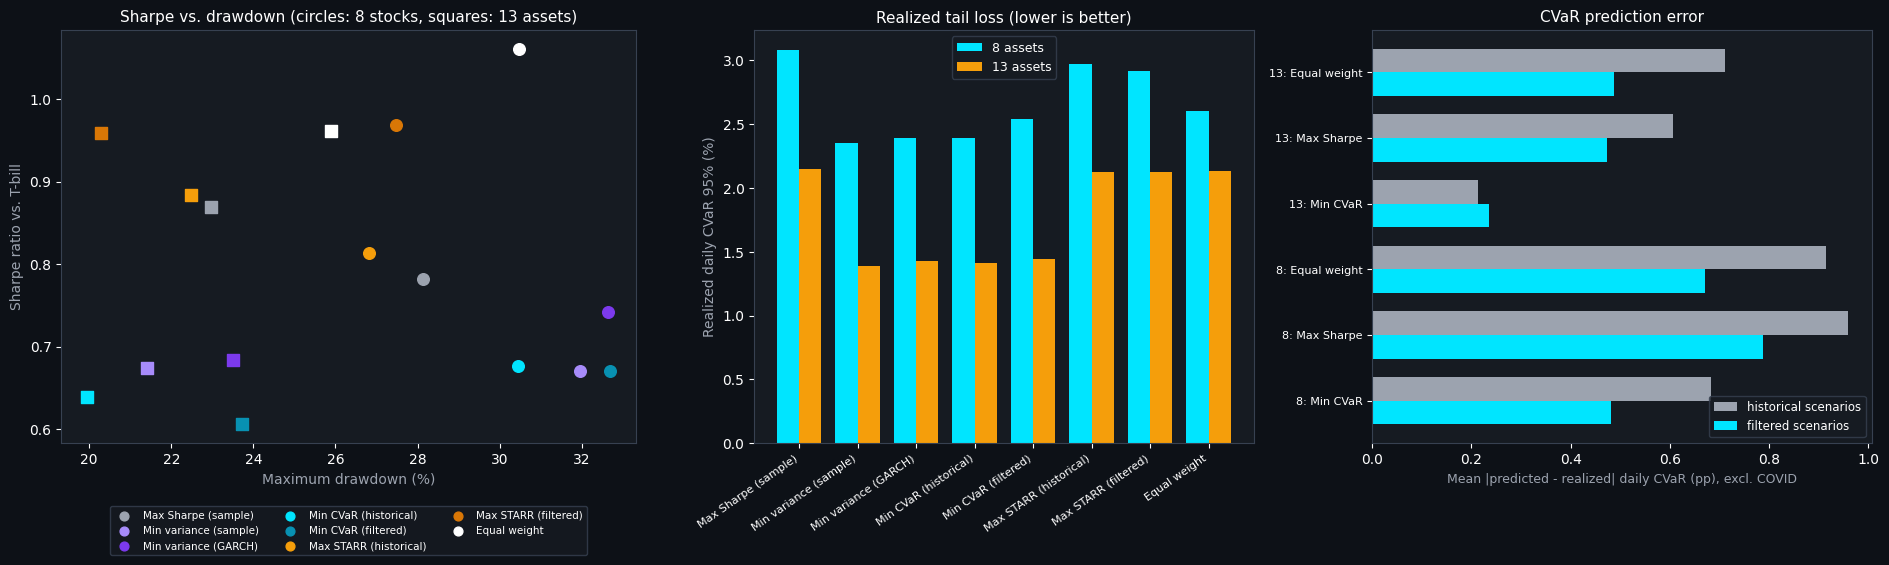

Saved chart_part7_cvar.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.8), gridspec_kw={'width_ratios': [1.15, 1, 1]})
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')
colors = {'Max Sharpe (sample)': '#9ca3af', 'Min variance (sample)': '#a78bfa', 'Min variance (GARCH)': '#7c3aed',
          'Min CVaR (historical)': '#00e5ff', 'Min CVaR (filtered)': '#0891b2', 'Max STARR (historical)': '#f59e0b',
          'Max STARR (filtered)': '#d97706', 'Equal weight': '#ffffff'}
ax = axes[0]
for uni, mk in (('8 assets', 'o'), ('13 assets', 's')):
    g = res[res.universe == uni]
    for _, r in g.iterrows():
        ax.scatter(-r['max_dd_%'], r['sharpe'], color=colors[r['strategy']], marker=mk, s=70, zorder=3)
ax.set_xlabel('Maximum drawdown (%)', color='#9ca3af')
ax.set_ylabel('Sharpe ratio vs. T-bill', color='#9ca3af')
ax.set_title('Sharpe vs. drawdown (circles: 8 stocks, squares: 13 assets)', color='white', fontsize=11)
for s, c in colors.items():
    ax.scatter([], [], color=c, label=s, s=40)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=3)
ax = axes[1]
order = STRATS
x = np.arange(len(order))
w = 0.38
for off, uni, col in ((-w/2, '8 assets', '#00e5ff'), (w/2, '13 assets', '#f59e0b')):
    vals = [res[(res.universe == uni) & (res.strategy == s)]['daily_cvar95_%'].iloc[0] for s in order]
    ax.bar(x + off, vals, w, color=col, label=uni)
ax.set_xticks(x)
ax.set_xticklabels(order, color='white', fontsize=8, rotation=35, ha='right')
ax.set_ylabel('Realized daily CVaR 95% (%)', color='#9ca3af')
ax.set_title('Realized tail loss (lower is better)', color='white', fontsize=11)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=9)
ax = axes[2]
cv_ex = cv[~cv['covid']]
g = cv_ex.groupby(['universe', 'portfolio'])[['err_hist', 'err_filt']].mean() * 100
labels = [f'{u.split()[0]}: {p.split(" (")[0]}' for u, p in g.index]
y = np.arange(len(g))[::-1]
ax.barh(y + 0.18, g['err_hist'], 0.36, color='#9ca3af', label='historical scenarios')
ax.barh(y - 0.18, g['err_filt'], 0.36, color='#00e5ff', label='filtered scenarios')
ax.set_yticks(y)
ax.set_yticklabels(labels, color='white', fontsize=8)
ax.set_xlabel('Mean |predicted - realized| daily CVaR (pp), excl. COVID', color='#9ca3af', fontsize=9)
ax.set_title('CVaR prediction error', color='white', fontsize=11)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=8.5, loc='lower right')
plt.tight_layout()
plt.savefig('chart_part7_cvar.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved chart_part7_cvar.png')

## 7. Summary and saved tables

In [9]:
res.to_csv('part7_cvar_results.csv', index=False)
ranks.to_csv('part7_ranks.csv', index=False)
boot_df.to_csv('part7_bootstrap_sharpe_differences.csv', index=False)
cv.to_csv('part7_cvar_prediction.csv', index=False)
pd.DataFrame([{'universe': f'{n} assets', 'strategy': s, 'window': k + 1, **{t: w_ for t, w_ in zip(tick[n], weights[n][s][k])}}
              for n in (8, 13) for s in STRATS for k in range(len(inputs[n]))]).to_csv('part7_weights.csv', index=False)
print('=' * 70)
print('PART 7 SUMMARY: CVAR-BASED PORTFOLIOS')
print('=' * 70)
print(res.round(3).to_string(index=False))
print()
print('Files saved: chart_part7_cvar.png, part7_cvar_results.csv, part7_ranks.csv, part7_bootstrap_sharpe_differences.csv, part7_cvar_prediction.csv, part7_weights.csv')

PART 7 SUMMARY: CVAR-BASED PORTFOLIOS
 universe               strategy  return_%  vol_%  sharpe  max_dd_%  daily_cvar95_%  worst_window_%  avg_turnover  median_holdings
 8 assets    Max Sharpe (sample)    19.278 21.142   0.782   -28.141           3.085         -17.386         0.383                5
 8 assets  Min variance (sample)    13.939 16.715   0.670   -31.948           2.351          -4.843         0.148                6
 8 assets   Min variance (GARCH)    15.246 16.869   0.741   -32.642           2.395          -9.906         0.544                6
 8 assets  Min CVaR (historical)    14.278 17.046   0.677   -30.454           2.392         -10.040         0.173                6
 8 assets    Min CVaR (filtered)    14.401 17.408   0.670   -32.680           2.538          -9.587         0.597                6
 8 assets Max STARR (historical)    19.543 20.656   0.814   -26.826           2.974         -16.487         0.386                4
 8 assets   Max STARR (filtered)    21.996 19